<a href="https://colab.research.google.com/github/diegoo7am/Curso-Intro-Python/blob/main/Modulo_02_Aplicaciones_Financieras/soluciones/2_2_pandas_descarga_activos_sol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[⬅ Volver al índice](https://colab.research.google.com/github/diegoo7am/Curso-Intro-Python/blob/main/indice.ipynb)

# Descarga y descripción de activos financieros

### CONCEPTOS TEÓRICOS

En este curso, partiremos de la premisa de que los **precios de una acción se comportan como una variable aleatoria, cuya función de distribución es lognormal**. Esta elección se justifica porque los precios no pueden ser negativos, y su comportamiento suele presentar una asimetría positiva. Además, dado que los precios de las acciones a menudo experimentan grandes fluctuaciones en el tiempo, el uso de una distribución lognormal permite capturar este comportamiento de manera más precisa. En consecuencia, asumiremos que el logaritmo de los precios sigue una distribución normal, lo cual será clave para los análisis posteriores.


Sin embargo, en lugar de trabajar directamente con precios, nos centraremos en los rendimientos. **Los rendimientos continuos de una acción, definidos como $ r_t = \ln \left( \frac{P_t}{P_{t-1}} \right) $, se aproximan a una distribución normal**. Esto nos proporciona una manera más conveniente de modelar y analizar el comportamiento de los activos financieros. **La distribución normal está caracterizada por dos parámetros fundamentales: la esperanza o media, que representa el rendimiento esperado o más probable de la acción, y la desviación estándar, que mide la dispersión de los rendimientos en torno a esa media, sirviendo como una primera aproximación al concepto de riesgo**. Cuanto mayor sea la desviación estándar, mayor será el riesgo asociado al activo.

Este enfoque nos permitirá, a lo largo del curso, modelar y simular diferentes escenarios en los que los rendimientos de una acción puedan variar en función de estos parámetros, ayudándonos a comprender mejor el equilibrio entre rentabilidad y riesgo en los mercados financieros.

### IMPLEMENTACIÓN EN PYTHON

Pandas es una librería muy popular entre los desarrolladores de Python, y sobre todo dentro del ámbito de Data Science y Machine Learning, ya que ofrece unas estructuras muy poderosas y flexibles que facilitan la manipulación y tratamiento de datos.

* Puedes encontrar la documentación de pandas [aquí](https://pandas.pydata.org/docs/index.html)
* En particular puedes ver unos tutoriales interesantes [aquí](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)

## 1. Lectura de datos

### Desde Excel y CSV

Supongamos que tenemos datos que provienen de dos **fuentes de datos distintas**, una en formato **Excel** y otra en formato **CSV**. Queremos leer ambos ficheros y unirlos con el objetivo de tener un único conjunto de datos.

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/data_02_parte_1.png" alt="Datos en Excel">

En Google Colab pandas ya viene instalado: solo hay que importarlo con el alias `pd`.

Los ficheros de datos del curso se leen directamente desde GitHub.

In [2]:
import os
import pandas as pd

# Dirección de la carpeta con los ficheros de datos del curso
RUTA_DATOS = "https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/data/"

In [4]:
data1 = pd.read_excel(RUTA_DATOS + "data_02_parte_1.xlsx")
data1

,Date,AAPL.O,MSFT.O
0,2010-01-01,NaN,NaN
1,2010-01-04,30.572827,30.950
2,2010-01-05,30.625684,30.960
3,2010-01-06,30.138541,30.770
4,2010-01-07,30.082827,30.452
...,...,...,...
2211,2018-06-25,182.170000,98.390
2212,2018-06-26,184.430000,99.080
2213,2018-06-27,184.160000,97.540
2214,2018-06-28,185.500000,98.630


Las estructuras que se utilizan en Pandas son:
* **DataFrame**: matriz bidimensional formado por series concatenadas en forma de filas y columnas. Cada una de las columnas es una serie
* **Series**: vector columna o matriz unidimensional que permite almacenar todo tipo de datos con un índice.

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/series_pandas.png" alt="Series y DataFrame" width="40%">

En nuestro caso, la información se ha guardado en el dataframe llamado `data1`. Mientras que `Date`, `AAPL.O` y `MSFT.O` son series.

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/estructura_pandas.png" alt="Estructura de un DataFrame">

Vamos a guardar el **dataframe** como un archivo de Excel nuevo.

- `index=False` evita que Pandas añada al Excel una columna extra con los índices `0, 1, 2, ....`

In [5]:
data1.to_excel("data1.xlsx", index=False)

In [ ]:
# Descarga el fichero a tu ordenador
from google.colab import files
files.download("data1.xlsx")

Vamos a recuperar el archivo que acabamos de guardar. Está en la carpeta `/content` de Colab: puedes verla en el icono de carpeta del panel izquierdo, y también subir desde ahí tus propios ficheros.

In [7]:
data1 = pd.read_excel("data1.xlsx")
data1

,Date,AAPL.O,MSFT.O
0,2010-01-01,NaN,NaN
1,2010-01-04,30.572827,30.950
2,2010-01-05,30.625684,30.960
3,2010-01-06,30.138541,30.770
4,2010-01-07,30.082827,30.452
...,...,...,...
2211,2018-06-25,182.170000,98.390
2212,2018-06-26,184.430000,99.080
2213,2018-06-27,184.160000,97.540
2214,2018-06-28,185.500000,98.630


In [ ]:
# Carpeta de trabajo actual
os.getcwd()

In [ ]:
# Ficheros que hay en la carpeta de trabajo
os.listdir()

También podemos conectar nuestro Google Drive para leer ficheros guardados en él (Colab te pedirá permiso):

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
# Ejemplo: pd.read_excel("/content/drive/MyDrive/data1.xlsx")

Una vez cargado, lo primero es ver la información general del dataframe:

In [11]:
# Tamaño del DataFrame (filas, columnas)
data1.shape

(2216, 3)

In [12]:
data1.info()

<class 'pandas.DataFrame'>
RangeIndex: 2216 entries, 0 to 2215
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    2216 non-null   datetime64[us]
 1   AAPL.O  2138 non-null   float64       
 2   MSFT.O  2138 non-null   float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 52.1 KB


Ahora vamos a ser un poco más específicos a la hora de indicar a Pandas cómo debe leer el fichero Excel. Indicaremos desde qué hoja queremos leer los datos y qué columna queremos que actúe como índice de los datos `index_col="Date"`.

In [13]:
data1 = pd.read_excel(RUTA_DATOS + "data_02_parte_1.xlsx", sheet_name="Datos", index_col="Date")
data1

,AAPL.O,MSFT.O
Date,,
2010-01-01,NaN,NaN
2010-01-04,30.572827,30.950
2010-01-05,30.625684,30.960
2010-01-06,30.138541,30.770
2010-01-07,30.082827,30.452
...,...,...
2018-06-25,182.170000,98.390
2018-06-26,184.430000,99.080
2018-06-27,184.160000,97.540


In [14]:
data1.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2216 entries, 2010-01-01 to 2018-06-29
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL.O  2138 non-null   float64
 1   MSFT.O  2138 non-null   float64
dtypes: float64(2)
memory usage: 51.9 KB


Podemos saber de qué tipo es un objeto usando el método `type`.

In [15]:
type(data1)

pandas.DataFrame

Podemos saber cuál es el índice de DataFrame consultando su propiedad `index`.

In [16]:
data1.index

DatetimeIndex(['2010-01-01', '2010-01-04', '2010-01-05', '2010-01-06',
               '2010-01-07', '2010-01-08', '2010-01-11', '2010-01-12',
               '2010-01-13', '2010-01-14',
               ...
               '2018-06-18', '2018-06-19', '2018-06-20', '2018-06-21',
               '2018-06-22', '2018-06-25', '2018-06-26', '2018-06-27',
               '2018-06-28', '2018-06-29'],
              dtype='datetime64[us]', name='Date', length=2216, freq=None)

#### Formato CSV

**EJERCICIO** Lee el fichero `data_02_parte_2.csv` y guárdalo en una variable llamada `data2`

In [17]:
data2 = pd.read_csv(RUTA_DATOS + "data_02_parte_2.csv")
data2

,Date,SPY,GLD
0,2010-01-01,NaN,NaN
1,2010-01-04,113.33,109.80
2,2010-01-05,113.63,109.70
3,2010-01-06,113.71,111.51
4,2010-01-07,114.19,110.82
...,...,...,...
2211,2018-06-25,271.00,119.89
2212,2018-06-26,271.60,119.26
2213,2018-06-27,269.35,118.58
2214,2018-06-28,270.89,118.22


Ahora tenemos los datos en dos dataframes separados `data1` y `data2`. Para poder unirlos en un único dataframe, usamos **pd.concat()**.

Vamos a ver cómo funciona con unos ejemplos:

#### EJEMPLO 1:

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/merging_concat_basic.png" alt="pd.concat básico" width="35%">

**¿Qué hace `pd.concat([])`?**
- **Columnas iguales, filas diferentes:** `pd.concat()` une DataFrames con las mismas columnas pero distintas filas.
- **Resultado:** Devuelve un DataFrame que contiene todas las filas y columnas de los DataFrames originales.

**EJERCICIO** Tienes dos DataFrames que contienen precios de cierre ajustados de las acciones de Apple (AAPL) y Microsoft (MSFT) en distintos periodos de tiempo. Los índices de ambos DataFrames son de tipo DatetimeIndex, y las fechas no se solapan: el primer DataFrame contiene datos de un rango de fechas hasta una cierta fecha, y el segundo empieza justo después de donde terminó el primero.

Se te pide concatenar estos DataFrames para formar un único DataFrame que contenga los precios de ambos periodos de tiempo.

In [18]:
# Creación del primer DataFrame con datos hasta el 2023-01-05
dates1 = pd.date_range(start="2023-01-01", end="2023-01-05", freq="D") # Rango de fechas diarias para el índice
dicc1 = {
    'AAPL': [150.75, 152.30, 153.40, 154.60, 155.10],
    'MSFT': [250.30, 252.40, 253.10, 254.80, 255.55]
}
df1 = pd.DataFrame(dicc1, index=dates1)

# Creación del segundo DataFrame con datos a partir del 2023-01-06
dates2 = pd.date_range(start="2023-01-06", end="2023-01-10", freq="D")
dicc2 = {
    'AAPL': [156.20, 157.30, 158.10, 159.00, 160.10],
    'MSFT': [256.50, 257.60, 258.10, 259.40, 260.50]
}
df2 = pd.DataFrame(dicc2, index=dates2)

In [19]:
# Combinar los DataFrames usando pd.concat: df2 se coloca debajo de df1
df_concatenado = pd.concat([df1, df2])

In [20]:
# Mostrar los DataFrames y el resultado final
print("DataFrame 1:\n", df1)
print("\nDataFrame 2:\n", df2)
print("\nDataFrame concatenado:\n", df_concatenado)

DataFrame 1:
               AAPL    MSFT
2023-01-01  150.75  250.30
2023-01-02  152.30  252.40
2023-01-03  153.40  253.10
2023-01-04  154.60  254.80
2023-01-05  155.10  255.55

DataFrame 2:
              AAPL   MSFT
2023-01-06  156.2  256.5
2023-01-07  157.3  257.6
2023-01-08  158.1  258.1
2023-01-09  159.0  259.4
2023-01-10  160.1  260.5

DataFrame concatenado:
               AAPL    MSFT
2023-01-01  150.75  250.30
2023-01-02  152.30  252.40
2023-01-03  153.40  253.10
2023-01-04  154.60  254.80
2023-01-05  155.10  255.55
2023-01-06  156.20  256.50
2023-01-07  157.30  257.60
2023-01-08  158.10  258.10
2023-01-09  159.00  259.40
2023-01-10  160.10  260.50


#### EJEMPLO 2:

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/merging_concat_axis1.png" alt="pd.concat con columnas distintas" width="40%">

**¿Qué hace `pd.concat()` cuando los DataFrames tienen columnas y filas comunes y no comunes?**
- **Columnas y filas comunes y no comunes:** Los DataFrames que se combinan pueden tener algunas columnas y filas en común, y otras que no coinciden.
- **Resultado:** `pd.concat()` crea un nuevo DataFrame que incluye todas las columnas y filas de ambos DataFrames. Cuando una columna o fila coincide entre los DataFrames, se combinan los datos disponibles. Si alguna columna o fila no tiene datos en uno de los DataFrames, se rellena con `NaN` en esas posiciones.

In [21]:
# Crear DataFrame 1 con precios de dos activos (AAPL y MSFT)
dicc1 = {
    'Fecha': ['2024-09-10', '2024-09-11', '2024-09-12'],
    'AAPL': [150, 152, 153],
    'MSFT': [300, 305, 310]
}
df1 = pd.DataFrame(dicc1)
df1 = df1.set_index('Fecha')


# Crear DataFrame 2 con precios de dos activos (MSFT y CSCO)
dicc2 = {
    'Fecha': ['2024-09-11', '2024-09-12', '2024-09-13'],
    'MSFT': [306, 311, 315],
    'CSCO': [50, 51, 52]
}
df2 = pd.DataFrame(dicc2)
df2 = df2.set_index('Fecha')

**EJERCICIO** concatena ambos dataframes

df1

↓

df2 debajo

axis=0 → filas

axis=1 → columnas

In [22]:
# axis=0: df2 se coloca debajo de df1
df_concatenado = pd.concat([df1, df2], axis=0)

print("DataFrame 1:\n", df1)
print("\nDataFrame 2:\n", df2)
print("\nDataFrame concatenado:\n", df_concatenado)

DataFrame 1:
             AAPL  MSFT
Fecha                 
2024-09-10   150   300
2024-09-11   152   305
2024-09-12   153   310

DataFrame 2:
             MSFT  CSCO
Fecha                 
2024-09-11   306    50
2024-09-12   311    51
2024-09-13   315    52

DataFrame concatenado:
              AAPL  MSFT  CSCO
Fecha                        
2024-09-10  150.0   300   NaN
2024-09-11  152.0   305   NaN
2024-09-12  153.0   310   NaN
2024-09-11    NaN   306  50.0
2024-09-12    NaN   311  51.0
2024-09-13    NaN   315  52.0


In [23]:
# axis=1: df2 se coloca a la derecha de df1 (se alinean por el índice)
df_concatenado = pd.concat([df1, df2], axis=1)

print("DataFrame 1:\n", df1)
print("\nDataFrame 2:\n", df2)
print("\nDataFrame concatenado:\n", df_concatenado)

DataFrame 1:
             AAPL  MSFT
Fecha                 
2024-09-10   150   300
2024-09-11   152   305
2024-09-12   153   310

DataFrame 2:
             MSFT  CSCO
Fecha                 
2024-09-11   306    50
2024-09-12   311    51
2024-09-13   315    52

DataFrame concatenado:
              AAPL   MSFT   MSFT  CSCO
Fecha                                
2024-09-10  150.0  300.0    NaN   NaN
2024-09-11  152.0  305.0  306.0  50.0
2024-09-12  153.0  310.0  311.0  51.0
2024-09-13    NaN    NaN  315.0  52.0


Prueba lo que pasa si añades el ignore_index=True del comando

In [24]:
df_concatenado = pd.concat([df1, df2], axis=0, ignore_index=True)

print("DataFrame 1:\n", df1)
print("\nDataFrame 2:\n", df2)
print("\nDataFrame concatenado:\n", df_concatenado)

DataFrame 1:
             AAPL  MSFT
Fecha                 
2024-09-10   150   300
2024-09-11   152   305
2024-09-12   153   310

DataFrame 2:
             MSFT  CSCO
Fecha                 
2024-09-11   306    50
2024-09-12   311    51
2024-09-13   315    52

DataFrame concatenado:
     AAPL  MSFT  CSCO
0  150.0   300   NaN
1  152.0   305   NaN
2  153.0   310   NaN
3    NaN   306  50.0
4    NaN   311  51.0
5    NaN   315  52.0


#### EJEMPLO 3:

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/merging_concat_axis1_inner.png" alt="pd.concat con join inner" width="40%">

**¿Qué hace `pd.concat()` con `join="inner"` y `axis=1`?**
- **Filas comunes:** Solo se mantienen las filas que existen en ambos DataFrames.
- **Resultado:** El DataFrame final incluye solo las columnas y filas donde hay datos en ambos DataFrames.

In [25]:
df_concatenado_inner = pd.concat([df1, df2], axis=1, join="inner")
df_concatenado_inner

,AAPL,MSFT,MSFT,CSCO
Fecha,,,,
2024-09-11,152,305,306,50
2024-09-12,153,310,311,51


Prueba los que pasa si eliminas axis=1 del comando

In [26]:
# Sin axis=1 se concatena por filas: con join="inner" solo quedan las columnas comunes
pd.concat([df1, df2], join="inner")

,MSFT
Fecha,
2024-09-10,300
2024-09-11,305
2024-09-12,310
2024-09-11,306
2024-09-12,311
2024-09-13,315


**EJERCICIO** Concatena data1 y data2

In [27]:
data = pd.concat([data1, data2], axis=1)
data

# data2 no tiene la fecha como índice, así que las filas no se alinean por fecha

,AAPL.O,MSFT.O,Date,SPY,GLD
2010-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN
2010-01-04 00:00:00,30.572827,30.950,NaN,NaN,NaN
2010-01-05 00:00:00,30.625684,30.960,NaN,NaN,NaN
2010-01-06 00:00:00,30.138541,30.770,NaN,NaN,NaN
2010-01-07 00:00:00,30.082827,30.452,NaN,NaN,NaN
...,...,...,...,...,...
2211,NaN,NaN,2018-06-25,271.00,119.89
2212,NaN,NaN,2018-06-26,271.60,119.26
2213,NaN,NaN,2018-06-27,269.35,118.58
2214,NaN,NaN,2018-06-28,270.89,118.22


Si ahora especificamos no solo qué columna queremos como índice, sino también que Pandas convierta automáticamente las cadenas que parezcan una fecha en un tipo fecha...

In [28]:
data2 = pd.read_csv(RUTA_DATOS + "data_02_parte_2.csv", index_col="Date", parse_dates=True)
data2

,SPY,GLD
Date,,
2010-01-01,NaN,NaN
2010-01-04,113.33,109.80
2010-01-05,113.63,109.70
2010-01-06,113.71,111.51
2010-01-07,114.19,110.82
...,...,...
2018-06-25,271.00,119.89
2018-06-26,271.60,119.26
2018-06-27,269.35,118.58


In [29]:
data2.index

DatetimeIndex(['2010-01-01', '2010-01-04', '2010-01-05', '2010-01-06',
               '2010-01-07', '2010-01-08', '2010-01-11', '2010-01-12',
               '2010-01-13', '2010-01-14',
               ...
               '2018-06-18', '2018-06-19', '2018-06-20', '2018-06-21',
               '2018-06-22', '2018-06-25', '2018-06-26', '2018-06-27',
               '2018-06-28', '2018-06-29'],
              dtype='datetime64[us]', name='Date', length=2216, freq=None)

In [30]:
data = pd.concat([data1, data2], axis=1)
data

,AAPL.O,MSFT.O,SPY,GLD
Date,,,,
2010-01-01,NaN,NaN,NaN,NaN
2010-01-04,30.572827,30.950,113.33,109.80
2010-01-05,30.625684,30.960,113.63,109.70
2010-01-06,30.138541,30.770,113.71,111.51
2010-01-07,30.082827,30.452,114.19,110.82
...,...,...,...,...
2018-06-25,182.170000,98.390,271.00,119.89
2018-06-26,184.430000,99.080,271.60,119.26
2018-06-27,184.160000,97.540,269.35,118.58


# 2. Slicing

In [31]:
# Consultamos las columnas que tiene nuestro DataFrame
data.columns

Index(['AAPL.O', 'MSFT.O', 'SPY', 'GLD'], dtype='str')

**EJERCICIO** Selecciona los datos de "AAPL.O" en una serie que denominaremos `a`

In [32]:
a = data["AAPL.O"]
a

Date
2010-01-01           NaN
2010-01-04     30.572827
2010-01-05     30.625684
2010-01-06     30.138541
2010-01-07     30.082827
                 ...    
2018-06-25    182.170000
2018-06-26    184.430000
2018-06-27    184.160000
2018-06-28    185.500000
2018-06-29    185.110000
Name: AAPL.O, Length: 2216, dtype: float64

In [33]:
type(a)

pandas.Series

In [34]:
data[["AAPL.O"]]  # Con doble corchete obtenemos un DataFrame

,AAPL.O
Date,
2010-01-01,NaN
2010-01-04,30.572827
2010-01-05,30.625684
2010-01-06,30.138541
2010-01-07,30.082827
...,...
2018-06-25,182.170000
2018-06-26,184.430000
2018-06-27,184.160000


In [35]:
type(data[["AAPL.O"]])

pandas.DataFrame

**EJERCICIO** Seleccionamos la serie de datos que tiene por nombre de columna "AAPL.O" y luego seleccionamos el valor que tiene en la fecha "2010-01-06".

In [36]:
data["AAPL.O"].loc["2010-01-06"]

np.float64(30.13854129)

Para extraer información de un ``DataFrame`` usaremos muy habitualmente las funciones ``loc`` e ``iloc``:

- ``loc``: nos permite hacer *slicing* utilizando los valores del índice y/o las columnas.

- ``iloc``: nos permite hacer *slicing* utilizand las posiciones en el índice y/o las columnas.

In [37]:
# Selecciona todas las filas y solo la columna "AAPL.O".
data.loc[:, "AAPL.O"]

Date
2010-01-01           NaN
2010-01-04     30.572827
2010-01-05     30.625684
2010-01-06     30.138541
2010-01-07     30.082827
                 ...    
2018-06-25    182.170000
2018-06-26    184.430000
2018-06-27    184.160000
2018-06-28    185.500000
2018-06-29    185.110000
Name: AAPL.O, Length: 2216, dtype: float64

In [38]:
# Selecciona todas las filas y solo la columna en la posición 0.
data.iloc[:, 0]

Date
2010-01-01           NaN
2010-01-04     30.572827
2010-01-05     30.625684
2010-01-06     30.138541
2010-01-07     30.082827
                 ...    
2018-06-25    182.170000
2018-06-26    184.430000
2018-06-27    184.160000
2018-06-28    185.500000
2018-06-29    185.110000
Name: AAPL.O, Length: 2216, dtype: float64

In [39]:
# Selecciona la fila con fecha "2018-06-25" y las columnas "AAPL.O" y "MSFT.O".
data.loc["2018-06-25", ["AAPL.O", "MSFT.O"]]

AAPL.O    182.17
MSFT.O     98.39
Name: 2018-06-25 00:00:00, dtype: float64

In [40]:
# Selecciona las filas con fechas entre "2018-05" y "2018-06-10" y las columnas "AAPL.O" y "MSFT.O".
data.loc["2018-05":"2018-06-10", ["AAPL.O", "MSFT.O"]]

,AAPL.O,MSFT.O
Date,,
2018-05-01,169.10,95.00
2018-05-02,176.57,93.51
2018-05-03,176.89,94.07
2018-05-04,183.83,95.16
2018-05-07,185.16,96.22
2018-05-08,186.05,95.81
2018-05-09,187.36,96.94
2018-05-10,190.04,97.91
2018-05-11,188.59,97.70


In [41]:
# Selecciona las 5 primeras filas.
data.iloc[:5]

,AAPL.O,MSFT.O,SPY,GLD
Date,,,,
2010-01-01,NaN,NaN,NaN,NaN
2010-01-04,30.572827,30.950,113.33,109.80
2010-01-05,30.625684,30.960,113.63,109.70
2010-01-06,30.138541,30.770,113.71,111.51
2010-01-07,30.082827,30.452,114.19,110.82


**EJERCICIO** Selecciona los 10 primeros días del 2018 usando `.loc` e `.iloc`

In [42]:
# .loc selecciona el año 2018 y .iloc los 10 primeros días
data.loc["2018"].iloc[:10]

,AAPL.O,MSFT.O,SPY,GLD
Date,,,,
2018-01-01,NaN,NaN,NaN,NaN
2018-01-02,172.26,85.95,268.77,125.15
2018-01-03,172.23,86.35,270.47,124.82
2018-01-04,173.03,87.11,271.61,125.46
2018-01-05,175.00,88.19,273.42,125.33
2018-01-08,174.35,88.28,273.92,125.31
2018-01-09,174.33,88.22,274.54,124.73
2018-01-10,174.29,87.82,274.12,125.03
2018-01-11,175.28,88.08,276.12,125.44


## 3. Inspección de los datos

In [43]:
data = pd.read_csv(RUTA_DATOS + "data_01.csv", index_col="Date", parse_dates=True)
data

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,NaN,129.397415,NaN
2019-07-02,48.913532,NaN,130.255753,NaN
2019-07-03,49.318890,NaN,131.095001,NaN
2019-07-05,49.275448,NaN,130.713547,NaN
2019-07-08,48.259693,NaN,130.618149,NaN
...,...,...,...,...
2024-06-24,NaN,215.630005,447.670013,NaN
2024-06-25,NaN,214.559998,450.950012,NaN
2024-06-26,NaN,212.580002,452.160004,NaN


Obtener información de los datos que contiene el DataFrame con ``info`` y ``describe``.
* ``info``: nos da información sobre los tipos y el rango de valores del índice y sobre el tipo y valores nulos de las columnas.
* ``describe``: nos da información estadística básica de las columnas numéricas.

In [44]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1258 entries, 2019-07-01 to 2024-06-28
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1212 non-null   float64
 1   GLD     1198 non-null   float64
 2   MSFT    1216 non-null   float64
 3   SPY     1079 non-null   float64
dtypes: float64(4)
memory usage: 49.1 KB


In [45]:
data.describe()

,AAPL,GLD,MSFT,SPY
count,1212.000000,1198.000000,1216.000000,1079.000000
mean,134.902860,171.328430,262.279147,380.759461
std,41.409409,17.497325,80.092659,58.007944
min,46.647964,133.210007,126.088112,209.257523
25%,113.291052,162.355003,206.069595,342.927185
50%,143.507835,170.485001,255.302002,393.155823
75%,169.450161,180.647495,318.535294,425.431168
max,214.240005,224.559998,452.850006,498.040863


Examinar datos nulos

Note: you may need to restart the kernel to use updated packages.


<Axes: >

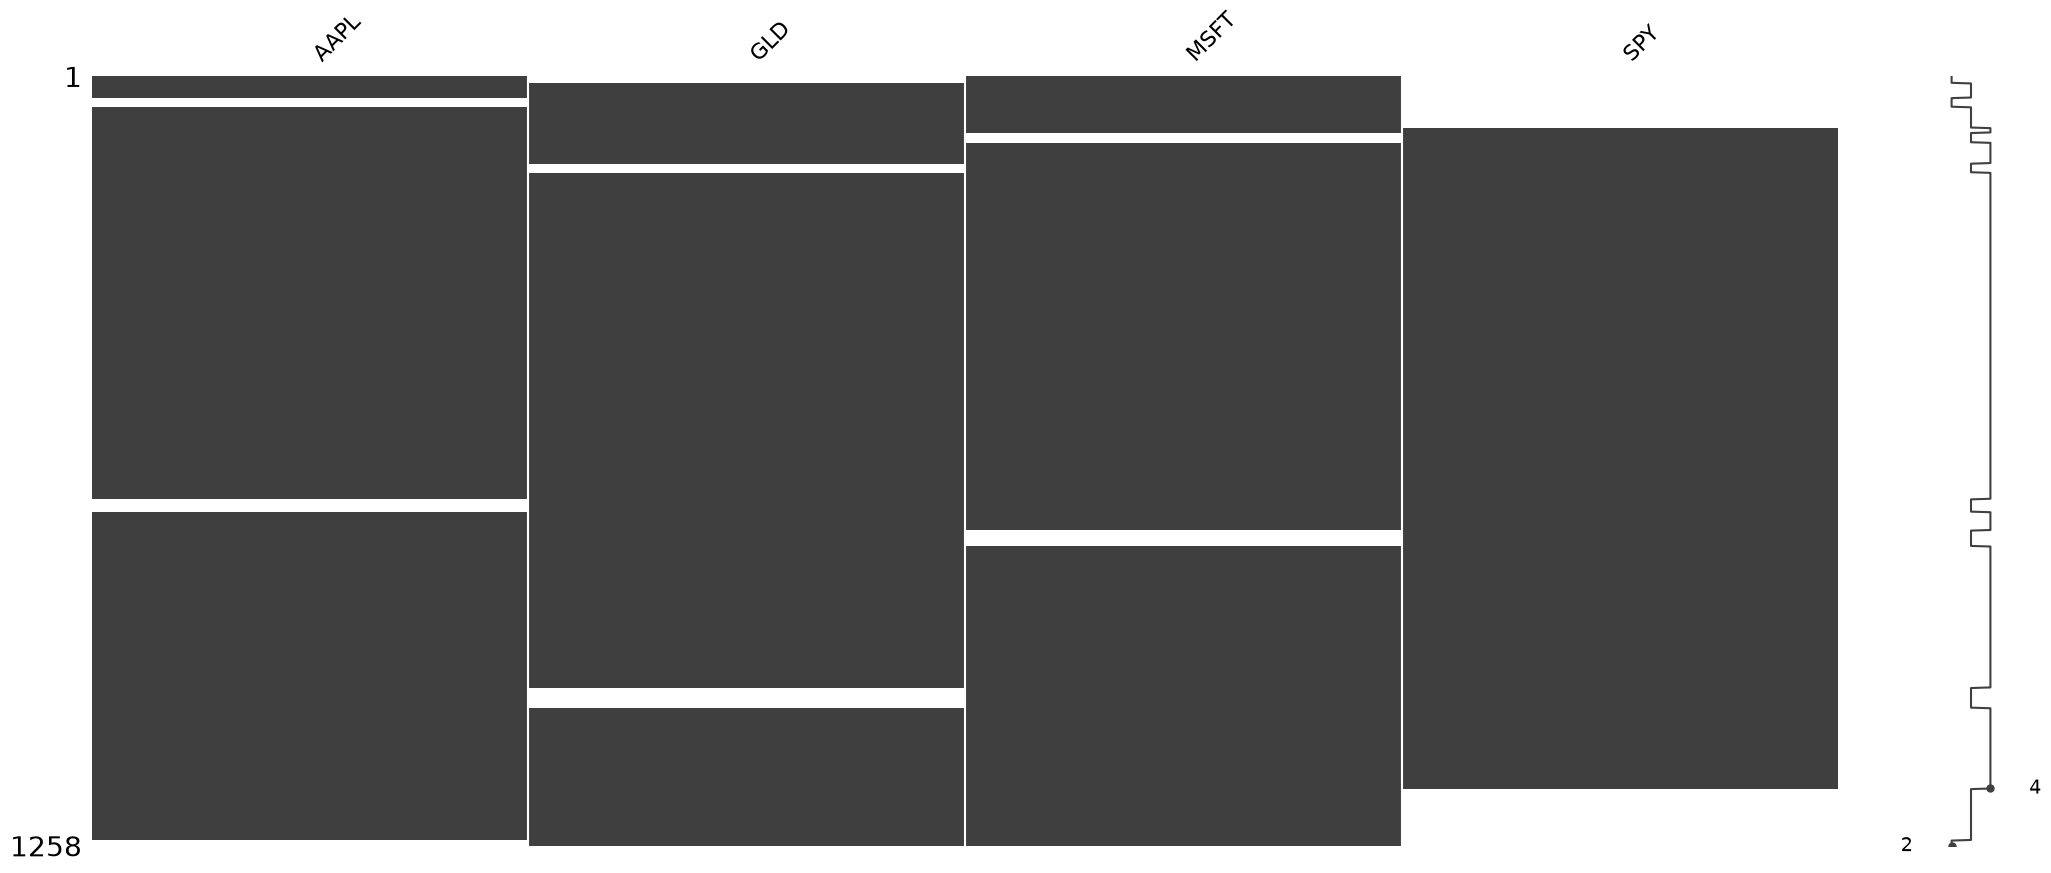

In [46]:
# missingno no viene instalado en Colab
%pip install -q missingno
import missingno as mso

mso.matrix(data)

In [47]:
# Contamos el número de nulos en cada columna.
data.isnull().sum()

AAPL     46
GLD      60
MSFT     42
SPY     179
dtype: int64

## EJERCICIO: Análisis inicial de Series de Precios de Activos Financieros:

1- **Descarga de Datos**:

  Descarga los archivos de precios históricos de tres activos financieros diferentes (AAPL.xlsx, MSFT.xlsx y CSCO.csv).

2- **Concatenación de datos**

  Selecciona únicamente la columna Cierre Ajustado de cada DataFrame, renombrándolas para que representen el ticker de cada activo (AAPL, MSFT, y CSCO).

    Junta todos en un único dataframe

3- **Inspección Inicial**:

  Muestra las primeras 10 filas del DataFrame resultante para revisar la estructura y contenido de los datos.

  Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.

4- **Slicing de datos**:

  Realiza un slicing para seleccionar solo las filas correspondientes al año 2024.

  Crea una nueva tabla que contenga los datos de precios de cierre de los activos seleccionados para las primeras 60 observaciones de 2024.

5- **Análisis Exploratorio Básico**:

  Calcula el número de días en los que los precios de cierre estuvieron disponibles para cada activo en 2024.

  Calcula la media de los precios de cierre para cada activo durante el año 2024, ignorando los valores nulos.

6- **Exportación de Datos**:

  Guarda el DataFrame final en un nuevo archivo CSV llamado precios_consolidados_2024.csv.

**¿Qué es el cierre ajustado (`Adj Close`)?** Es el precio de cierre corregido por los dividendos y los *splits* (divisiones de acciones). Es el que se usa para calcular rentabilidades, porque refleja lo que realmente ha ganado el inversor.

1- **Descarga de Datos**:

  Descarga los archivos de precios históricos de tres activos financieros diferentes (AAPL.xlsx, MSFT.xlsx y CSCO.csv).

In [48]:
# 1. Cargar los datos desde la carpeta de datos y establecer la columna 'Date' como índice
df_aapl = pd.read_excel(RUTA_DATOS + "AAPL.xlsx", index_col="Date", parse_dates=True)
df_msft = pd.read_excel(RUTA_DATOS + "MSFT.xlsx", index_col="Date", parse_dates=True)
df_csco = pd.read_csv(RUTA_DATOS + "CSCO.csv", index_col="Date", parse_dates=True)

In [49]:
df_aapl.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2022-01-03,177.830002,182.880005,177.710007,182.009995,179.273590,104487900
2022-01-04,182.630005,182.940002,179.119995,179.699997,176.998337,99310400
2022-01-05,179.610001,180.169998,174.639999,174.919998,172.290207,94537600
2022-01-06,172.699997,175.300003,171.639999,172.000000,169.414108,96904000
2022-01-07,172.889999,174.139999,171.029999,172.169998,169.581543,86709100


2- **Concatenación de datos**

  Selecciona únicamente la columna Cierre Ajustado de cada DataFrame, renombrándolas para que representen el ticker de cada activo (AAPL, MSFT, y CSCO).

  Junta todos en un único dataframe

In [50]:
# 2. Seleccionar solo la columna 'Adj Close' de cada DataFrame y renombrarla con el ticker
df_aapl = df_aapl[["Adj Close"]].rename(columns={"Adj Close": "AAPL"})
df_msft = df_msft[["Adj Close"]].rename(columns={"Adj Close": "MSFT"})
df_csco = df_csco[["Adj Close"]].rename(columns={"Adj Close": "CSCO"})

In [51]:
# Concatenar los DataFrames por columnas
df_concatenado = pd.concat([df_aapl, df_msft, df_csco], axis=1)

3- **Inspección Inicial**:

  Muestra las primeras 10 filas del DataFrame resultante para revisar la estructura y contenido de los datos.

  Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.

In [52]:
# Verificar la concatenación: primeras 10 filas
df_concatenado.head(10)

,AAPL,MSFT,CSCO
Date,,,
2022-01-03,179.273590,NaN,NaN
2022-01-04,176.998337,NaN,NaN
2022-01-05,172.290207,NaN,NaN
2022-01-06,169.414108,NaN,NaN
2022-01-07,169.581543,NaN,NaN
2022-01-10,169.601257,NaN,NaN
2022-01-11,172.447815,NaN,NaN
2022-01-12,172.891037,NaN,NaN
2022-01-13,169.601257,NaN,NaN


In [53]:
# Número de valores nulos (NaN) de cada columna
df_concatenado.isnull().sum()

AAPL      0
MSFT    251
CSCO    156
dtype: int64

In [54]:
# Tipo de datos y número de valores no nulos de cada columna
df_concatenado.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 678 entries, 2022-01-03 to 2024-09-13
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    678 non-null    float64
 1   MSFT    427 non-null    float64
 2   CSCO    522 non-null    float64
dtypes: float64(3)
memory usage: 21.2 KB


In [55]:
# Estadísticos básicos de cada columna: media, desviación típica, mínimo, máximo...
df_concatenado.describe()

,AAPL,MSFT,CSCO
count,678.000000,427.000000,522.000000
mean,170.866642,354.692213,46.838985
std,23.752284,62.074594,3.887891
min,123.855095,219.158356,37.182934
25%,152.270084,316.031372,44.764562
50%,170.221504,357.844025,47.086695
75%,185.199730,411.318283,49.259592
max,234.548523,466.718781,56.040001


4- **Slicing de datos**:

  Realiza un slicing para seleccionar solo las filas correspondientes al año 2024.

  Crea una nueva tabla que contenga los datos de precios de cierre de los activos seleccionados para las primeras 60 observaciones de 2024.

In [56]:
# Selecciono los datos de 2024
df_2024 = df_concatenado.loc["2024"]
df_2024

,AAPL,MSFT,CSCO
Date,,,
2024-01-02,184.938217,368.854095,49.291550
2024-01-03,183.553482,368.585571,49.675102
2024-01-04,181.222336,365.940002,49.252216
2024-01-05,180.495071,365.751038,49.262051
2024-01-08,184.858521,372.653351,49.625935
...,...,...,...
2024-09-09,220.910004,405.720001,NaN
2024-09-10,220.110001,414.200012,NaN
2024-09-11,222.660004,423.040009,NaN


In [57]:
# Selecciono los datos de 2024 y los primeros 60 días
df_60 = df_2024.iloc[:60]
df_60

,AAPL,MSFT,CSCO
Date,,,
2024-01-02,184.938217,368.854095,49.291550
2024-01-03,183.553482,368.585571,49.675102
2024-01-04,181.222336,365.940002,49.252216
2024-01-05,180.495071,365.751038,49.262051
2024-01-08,184.858521,372.653351,49.625935
2024-01-09,184.440109,373.747345,49.085026
2024-01-10,185.486145,380.689423,49.409573
2024-01-11,184.888412,382.539307,49.606262
2024-01-12,185.217163,386.358429,49.507919


5- **Análisis Exploratorio Básico**:

  Calcula el número de días en los que los precios de cierre estuvieron disponibles para cada activo en 2024.

  Calcula la media de los precios de cierre para cada activo durante el año 2024, ignorando los valores nulos.

In [58]:
df_2024.info()  # Número de días con precio de cierre disponible (Non-Null Count)

<class 'pandas.DataFrame'>
DatetimeIndex: 177 entries, 2024-01-02 to 2024-09-13
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    177 non-null    float64
 1   MSFT    177 non-null    float64
 2   CSCO    124 non-null    float64
dtypes: float64(3)
memory usage: 5.5 KB


In [59]:
df_2024.mean(skipna=True)  # Precio medio de cierre ignorando los valores nulos

AAPL    195.430356
MSFT    416.357165
CSCO     48.046718
dtype: float64

In [60]:
# Estadística descriptiva de los precios de 2024
df_2024.describe()

,AAPL,MSFT,CSCO
count,177.000000,177.000000,124.000000
mean,195.430356,416.357165,48.046718
std,21.081554,19.556515,1.465662
min,164.585999,365.751038,45.133335
25%,180.296478,405.097839,47.024632
50%,189.620514,414.005676,48.065247
75%,217.708008,424.746948,49.156325
max,234.548523,466.718781,51.465023


6- **Exportación de Datos**:

  Guarda el DataFrame final en un nuevo archivo CSV llamado precios_consolidados_2024.csv.

In [61]:
# Guardamos el DataFrame en un fichero CSV
df_2024.to_csv("precios_consolidados_2024.csv")

# Lo volvemos a leer para comprobar que se ha guardado bien
pd.read_csv("precios_consolidados_2024.csv", index_col="Date", parse_dates=True).head()

,AAPL,MSFT,CSCO
Date,,,
2024-01-02,184.938217,368.854095,49.291550
2024-01-03,183.553482,368.585571,49.675102
2024-01-04,181.222336,365.940002,49.252216
2024-01-05,180.495071,365.751038,49.262051
2024-01-08,184.858521,372.653351,49.625935


## 4. Limpieza de datos

¿Qué podemos hacer ahora?
* Eliminar las filas que no contienen datos.
* Rellenar los datos faltantes.
* Remuestrear los datos a una frecuencia menor.
* Obtener los datos desde una fuente de datos más fiable.

Eliminar las filas que no contienen datos

<Axes: >

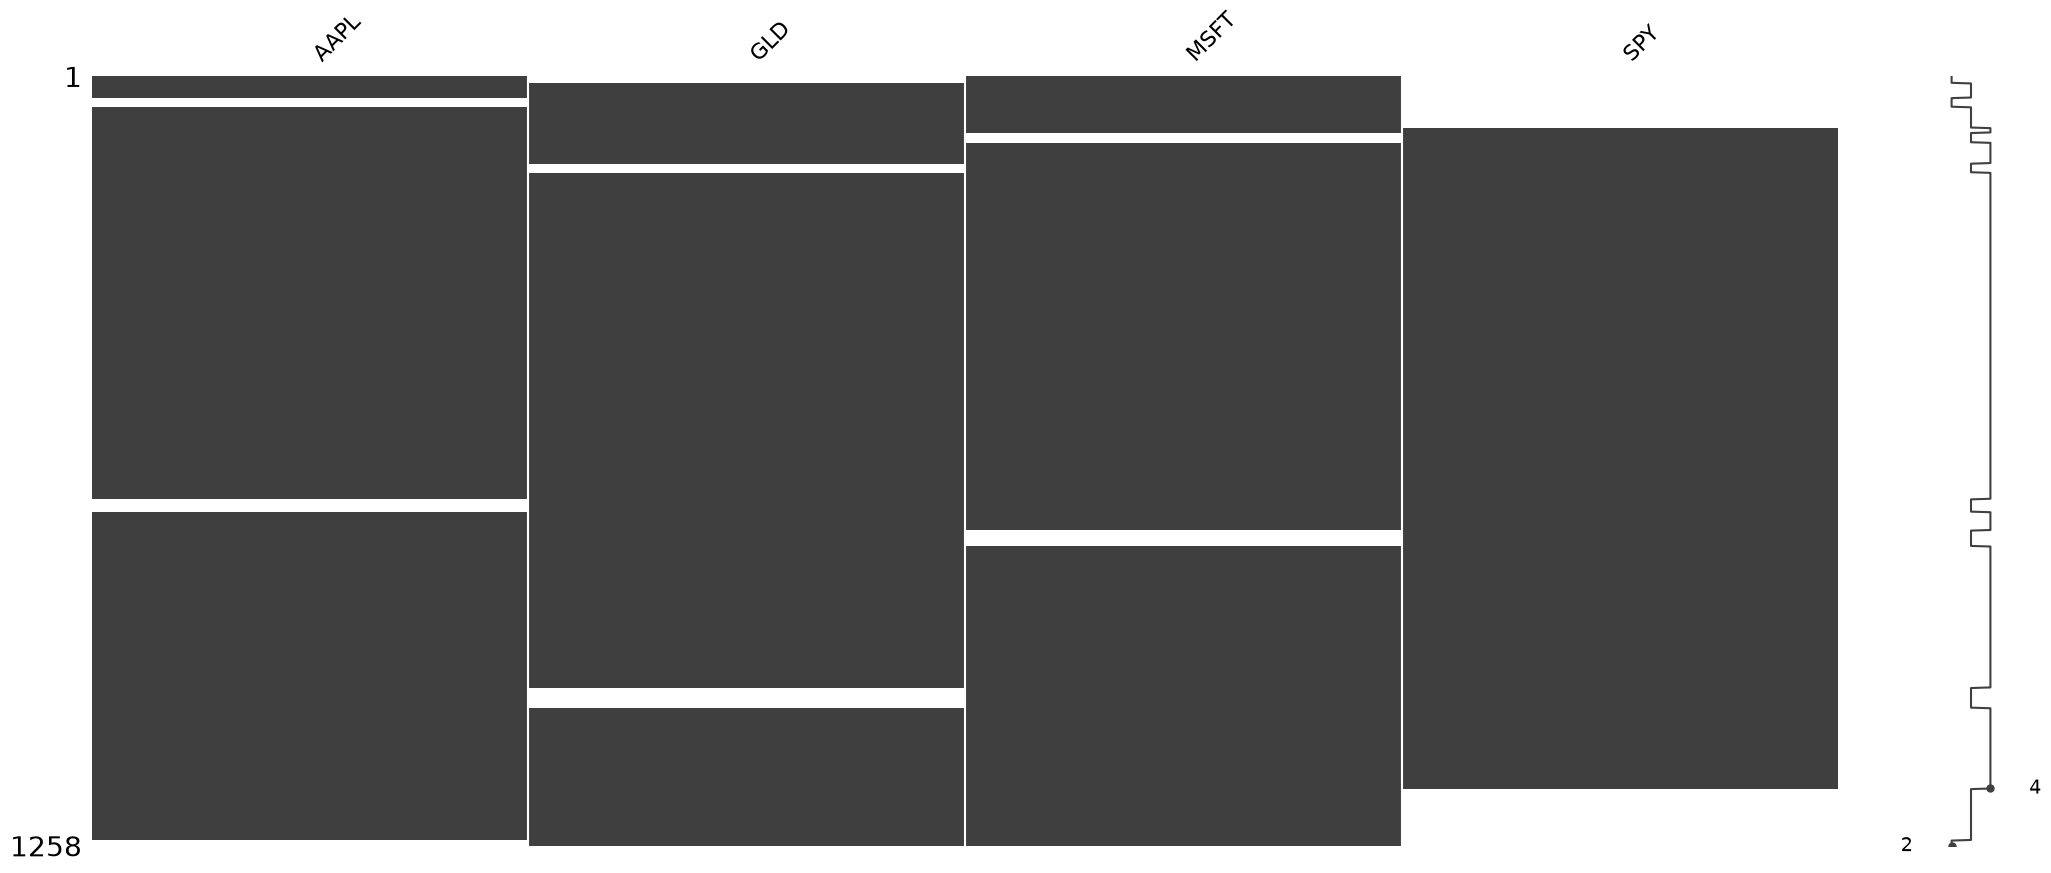

In [62]:
# Veamos los datos
mso.matrix(data)

`data.dropna(how="any",axis=1)`
Borra las columnas que tenga al menos un NaN


Tengo dos opciones para `how`:

how="any" → elimina si hay al menos un NaN

how="all" → elimina solo si todos los valores son NaN

In [63]:
# Eliminamos las columnas que tengan al menos un valor nulo.
data.dropna(how="any", axis=1)

""
Date
2019-07-01
2019-07-02
2019-07-03
2019-07-05
2019-07-08
...
2024-06-24
2024-06-25
2024-06-26


<Axes: >

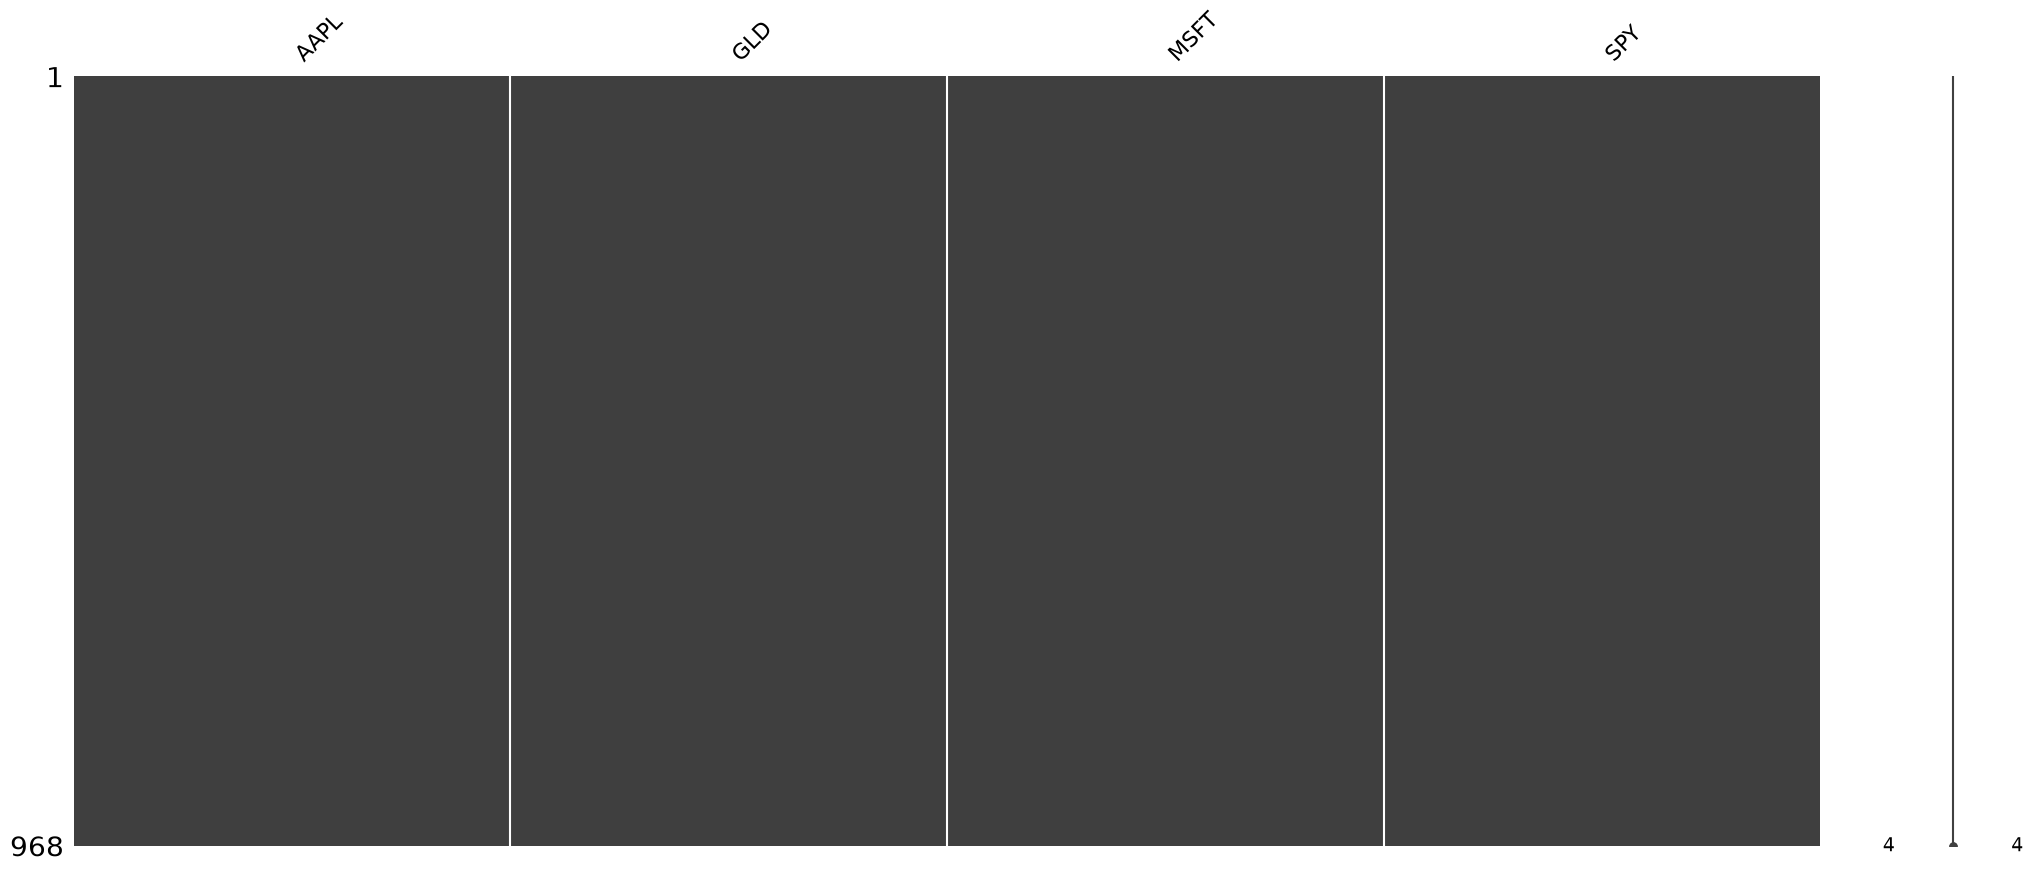

In [64]:
# Eliminamos las filas que tengan al menos un valor nulo.
mso.matrix(data.dropna(how="any", axis=0))

Rellenar datos faltantes.

**Cuidado con rellenar datos... depende del caso de uso en el que se está trabajando.**

In [65]:
# Rellena los NaN de cada columna con un cero.
data.fillna(0)

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,0.000000,129.397415,0.0
2019-07-02,48.913532,0.000000,130.255753,0.0
2019-07-03,49.318890,0.000000,131.095001,0.0
2019-07-05,49.275448,0.000000,130.713547,0.0
2019-07-08,48.259693,0.000000,130.618149,0.0
...,...,...,...,...
2024-06-24,0.000000,215.630005,447.670013,0.0
2024-06-25,0.000000,214.559998,450.950012,0.0
2024-06-26,0.000000,212.580002,452.160004,0.0


In [66]:
# Rellena los NaN de cada columna con la media de cada columna.
data.fillna(data.mean())

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,171.328430,129.397415,380.759461
2019-07-02,48.913532,171.328430,130.255753,380.759461
2019-07-03,49.318890,171.328430,131.095001,380.759461
2019-07-05,49.275448,171.328430,130.713547,380.759461
2019-07-08,48.259693,171.328430,130.618149,380.759461
...,...,...,...,...
2024-06-24,134.902860,215.630005,447.670013,380.759461
2024-06-25,134.902860,214.559998,450.950012,380.759461
2024-06-26,134.902860,212.580002,452.160004,380.759461


In [67]:
# Rellena los NaN de cada columna con el último valor conocido hacia adelante.
data.ffill()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,NaN,129.397415,NaN
2019-07-02,48.913532,NaN,130.255753,NaN
2019-07-03,49.318890,NaN,131.095001,NaN
2019-07-05,49.275448,NaN,130.713547,NaN
2019-07-08,48.259693,NaN,130.618149,NaN
...,...,...,...,...
2024-06-24,214.240005,215.630005,447.670013,490.965698
2024-06-25,214.240005,214.559998,450.950012,490.965698
2024-06-26,214.240005,212.580002,452.160004,490.965698


In [68]:
# Rellena los NaN de cada columna con el último valor conocido hacia atrás.
data.bfill()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,136.479996,129.397415,282.404022
2019-07-02,48.913532,136.479996,130.255753,282.404022
2019-07-03,49.318890,136.479996,131.095001,282.404022
2019-07-05,49.275448,136.479996,130.713547,282.404022
2019-07-08,48.259693,136.479996,130.618149,282.404022
...,...,...,...,...
2024-06-24,NaN,215.630005,447.670013,NaN
2024-06-25,NaN,214.559998,450.950012,NaN
2024-06-26,NaN,212.580002,452.160004,NaN


In [69]:
# Rellena los NaN de cada columna con el último valor conocido primero hacia delante y luego hacia atrás.
data.ffill().bfill()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,136.479996,129.397415,282.404022
2019-07-02,48.913532,136.479996,130.255753,282.404022
2019-07-03,49.318890,136.479996,131.095001,282.404022
2019-07-05,49.275448,136.479996,130.713547,282.404022
2019-07-08,48.259693,136.479996,130.618149,282.404022
...,...,...,...,...
2024-06-24,214.240005,215.630005,447.670013,490.965698
2024-06-25,214.240005,214.559998,450.950012,490.965698
2024-06-26,214.240005,212.580002,452.160004,490.965698


Remuestrear los datos a una frecuencia menor.

In [70]:
# Remuestrea los datos de días a semanas usando el último valor conocido el miércoles de cada semana.
data.resample("W-WED").last()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-03,49.318890,NaN,131.095001,NaN
2019-07-10,49.034176,NaN,131.466949,NaN
2019-07-17,49.063133,NaN,129.960129,NaN
2019-07-24,50.346706,134.369995,134.204056,NaN
2019-07-31,51.401085,133.210007,129.960129,NaN
...,...,...,...,...
2024-06-05,195.869995,217.820007,424.010010,NaN
2024-06-12,213.070007,214.720001,441.059998,NaN
2024-06-19,214.240005,215.470001,446.339996,NaN


In [71]:
data.resample("W-MON").last()   # lunes
data.resample("W-TUE").last()   # martes
data.resample("W-WED").last()   # miércoles
data.resample("W-THU").last()   # jueves
data.resample("W-FRI").last()   # viernes
data.resample("W-SAT").last()   # sábado
data.resample("W-SUN").last()   # domingo

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-07,49.275448,NaN,130.713547,NaN
2019-07-14,49.051064,NaN,132.468353,NaN
2019-07-21,48.879753,134.470001,130.293915,NaN
2019-07-28,50.122318,133.639999,134.795349,NaN
2019-08-04,49.224781,135.889999,130.560959,NaN
...,...,...,...,...
2024-06-02,192.250000,215.300003,415.130005,NaN
2024-06-09,196.889999,211.600006,423.850006,NaN
2024-06-16,214.240005,215.729996,442.570007,NaN


Otras frecuencias útiles

In [72]:
data.resample("D").last()       # diario
data.resample("B").last()       # día hábil
data.resample("W-FRI").last()   # semanal, viernes
data.resample("ME").last()      # fin de mes
data.resample("MS").first()     # inicio de mes
data.resample("QE").last()      # fin de trimestre
data.resample("YE").last()      # fin de año

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-12-31,71.332909,142.899994,151.412109,300.326996
2020-12-31,130.044678,178.360001,215.813828,355.381714
2021-12-31,175.102829,170.960007,329.066284,457.478516
2022-12-31,128.868332,169.639999,236.846252,374.330170
2023-12-31,192.024185,191.169998,374.670074,472.314026
2024-12-31,214.240005,215.009995,446.950012,490.965698


También puedes combinar resample() con distintas operaciones:

In [73]:
# Remuestrea los datos usando el último valor conocido en la fecha de fin de mes.
data.resample("ME").last()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-31,51.401085,133.210007,129.960129,NaN
2019-08-31,50.947308,143.750000,131.914291,NaN
2019-09-30,54.243515,138.869995,133.033829,NaN
2019-10-31,60.247440,142.429993,137.186630,281.651917
2019-11-30,64.919876,137.860001,139.664993,291.847198
2019-12-31,71.332909,142.899994,151.412109,300.326996
2020-01-31,75.185577,147.119995,163.442474,300.205719
2020-02-29,66.561684,148.380005,155.975128,276.439667
2020-03-31,61.918247,148.050003,151.835297,241.920288


In [74]:
data.resample("ME").last()      # último dato del mes
data.resample("ME").first()     # primer dato del mes
data.resample("ME").mean()      # media mensual
data.resample("ME").max()       # máximo mensual
data.resample("ME").min()       # mínimo mensual
data.resample("ME").sum()       # suma mensual

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-31,1089.295578,1343.239990,2897.575500,0.000000
2019-08-31,688.509792,3120.089996,2866.982132,0.000000
2019-09-30,693.637478,2841.209991,2643.175583,0.000000
2019-10-31,1310.638477,3240.119980,3064.160751,564.055939
2019-11-30,1274.672607,2771.409988,829.617203,5762.234375
2019-12-31,1410.635319,2931.819992,2821.728195,6201.088501
2020-01-31,1591.172050,2196.559998,3306.659668,6407.090729
2020-02-29,1439.326820,1524.550003,3263.893967,5803.945129
2020-03-31,1405.882038,3291.089981,3231.171600,5446.529068


Obtener los datos desde una fuente más fiable

**La API de Yahoo Finance** permite acceder programáticamente a datos financieros, incluidos precios históricos, cotizaciones en tiempo real, datos fundamentales y noticias de mercado. En Python utilizaremos la librería `yfinance`.

Para más información de los datos que proporciona lo puedes ver en la [documentación de yfinance](https://ranaroussi.github.io/yfinance/)

In [75]:
%pip install -q yfinance

Note: you may need to restart the kernel to use updated packages.


**Importante:** en el curso trabajamos siempre con el precio de cierre ajustado (`Adj Close`), que corrige el precio por dividendos y *splits*.

- `auto_adjust=False` → `yf.download()` devuelve las columnas `Close` (sin ajustar) y `Adj Close`.
- `auto_adjust=True` (valor por defecto en las versiones actuales de `yfinance`) → la columna `Adj Close` desaparece y `Close` pasa a contener el precio ajustado.

Por eso indicaremos siempre `auto_adjust=False` y seleccionaremos la columna `Adj Close`.

In [76]:
import yfinance as yf

data = yf.download(["AAPL", "GLD", "MSFT", "SPY"], start="2018-12-31", end="2023-12-31", auto_adjust=False)
data

[                       0%                       ]

[**********************50%                       ]  2 of 4 completed

[**********************75%***********            ]  3 of 4 completed

[*********************100%***********************]  4 of 4 completed

Price        Adj Close                                           Close  \
Ticker            AAPL         GLD        MSFT         SPY        AAPL   
Date                                                                     
2018-12-31   37.394253  121.250000   94.434532  223.019562   39.435001   
2019-01-02   37.436920  121.330002   94.016144  223.251602   39.480000   
2019-01-03   33.707924  122.430000   90.557472  217.924164   35.547501   
2019-01-04   35.146900  121.440002   94.769257  225.223740   37.064999   
2019-01-07   35.068657  121.860001   94.890099  226.999481   36.982498   
...                ...         ...         ...         ...         ...   
2023-12-22  191.268143  190.270004  366.750305  458.641022  193.600006   
2023-12-26  190.724747  191.720001  366.828705  460.577698  193.050003   
2023-12-27  190.823547  192.589996  366.251099  461.410431  193.149994   
2023-12-28  191.248367  191.470001  367.435730  461.584778  193.580002   
2023-12-29  190.211014  191.169998  368.179901  460.248413  192.529999   

Price                                                 High              ...  \
Ticker             GLD        MSFT         SPY        AAPL         GLD  ...   
Date                                                                    ...   
2018-12-31  121.250000  101.570000  249.919998   39.840000  121.260002  ...   
2019-01-02  121.330002  101.120003  250.179993   39.712502  121.750000  ...   
2019-01-03  122.430000   97.400002  244.210007   36.430000  122.459999  ...   
2019-01-04  121.440002  101.930000  252.389999   37.137501  121.599998  ...   
2019-01-07  121.860001  102.059998  254.380005   37.207500  122.220001  ...   
...                ...         ...         ...         ...         ...  ...   
2023-12-22  190.270004  374.579987  473.649994  195.410004  191.880005  ...   
2023-12-26  191.720001  374.660004  475.649994  193.889999  191.740005  ...   
2023-12-27  192.589996  374.070007  476.510010  193.500000  193.179993  ...   
2023-12-28  191.470001  375.279999  476.690002  194.660004  192.889999  ...   
2023-12-29  191.169998  376.040009  475.309998  194.399994  191.639999  ...   

Price              Low                    Open                          \
Ticker            MSFT         SPY        AAPL         GLD        MSFT   
Date                                                                     
2018-12-31  100.440002  247.470001   39.632500  120.980003  101.290001   
2019-01-02   98.940002  245.949997   38.722500  121.349998   99.550003   
2019-01-03   97.199997  243.669998   35.994999  121.779999  100.099998   
2019-01-04   98.930000  247.169998   36.132500  121.320000   99.720001   
2019-01-07  100.980003  251.690002   37.174999  122.160004  101.639999   
...                ...         ...         ...         ...         ...   
2023-12-22  372.709991  471.700012  195.179993  191.600006  373.679993   
2023-12-26  373.500000  473.989990  193.610001  190.970001  375.000000   
2023-12-27  372.809998  474.890015  192.490005  191.770004  373.690002   
2023-12-28  374.160004  476.260010  194.139999  192.339996  375.369995   
2023-12-29  373.480011  473.299988  193.899994  190.990005  376.000000   

Price                      Volume                                 
Ticker             SPY       AAPL       GLD      MSFT        SPY  
Date                                                              
2018-12-31  249.559998  140014000   8449400  33173800  144299400  
2019-01-02  245.979996  148158800  12776200  35329300  126925200  
2019-01-03  248.229996  365248800  15440800  42579100  144140700  
2019-01-04  247.589996  234428400  13334000  44060600  142628800  
2019-01-07  252.690002  219111200   7473600  35656100  103139100  
...                ...        ...       ...       ...        ...  
2023-12-22  473.859985   37149600   7176300  17107500   67160400  
2023-12-26  474.070007   28919300   4502700  12673100   55387000  
2023-12-27  475.440002   48087700   5813300  14905400   68000300  
2023-12-28  476

In [77]:
data = data.loc[:, "Adj Close"]
data

Ticker,AAPL,GLD,MSFT,SPY
Date,,,,
2018-12-31,37.394253,121.250000,94.434532,223.019562
2019-01-02,37.436920,121.330002,94.016144,223.251602
2019-01-03,33.707924,122.430000,90.557472,217.924164
2019-01-04,35.146900,121.440002,94.769257,225.223740
2019-01-07,35.068657,121.860001,94.890099,226.999481
...,...,...,...,...
2023-12-22,191.268143,190.270004,366.750305,458.641022
2023-12-26,190.724747,191.720001,366.828705,460.577698
2023-12-27,190.823547,192.589996,366.251099,461.410431


In [78]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1259 entries, 2018-12-31 to 2023-12-29
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1259 non-null   float64
 1   GLD     1259 non-null   float64
 2   MSFT    1259 non-null   float64
 3   SPY     1259 non-null   float64
dtypes: float64(4)
memory usage: 49.2 KB


In [79]:
data.describe()

Ticker,AAPL,GLD,MSFT,SPY
count,1259.000000,1259.000000,1259.000000,1259.000000
mean,120.038791,162.905488,226.821682,349.683788
std,46.294755,18.664851,71.990887,65.173730
min,33.707924,119.940002,90.557472,203.911911
25%,74.447426,153.270004,164.429794,284.481445
50%,131.049606,167.770004,234.315262,366.689209
75%,156.233315,177.264999,282.351746,405.972427
max,195.723816,193.889999,374.700714,461.584778


## 5. Visualización

Hasta ahora hemos visto cómo descargar y limpiar los datos, pero nos falta un ejercicio importante que es el que más ayuda a analizar los datos: **visualizarlos**.

Veremos dos formas de visualizar datos:

- Usando los **métodos de visualización de Pandas** para un análisis rápido e inicial.

- Usando **Matplotlib** para crear gráficos más desarrollados y personalizados.

Para ver la documentación de cómo hacer gráficos con Pandas ver [Visualización con Pandas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/04_plotting.html)

Representa gráficamente los datos contenidos en el DataFrame data.
'data.plot(...)'

Pandas utilizará normalmente:
- el índice (Fecha) como eje X;
- las columnas (AAPL, GLD, MSFT, SPY) como variables a representar.

<Axes: xlabel='Date'>

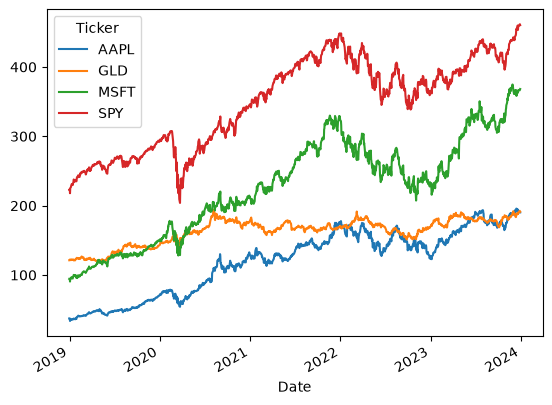

In [80]:
data.plot()

`figsize=(12, 4)`

Controla el tamaño de la figura: figsize=(ancho, alto), 12 pulgadas de ancho y 4 pulgadas de alto.

`subplots=True`

crea un gráfico diferente para cada columna

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

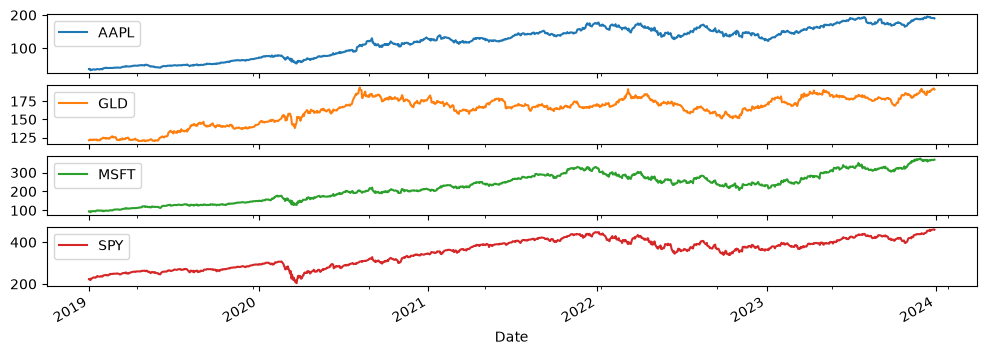

In [81]:
data.plot(figsize=(12, 4), subplots=True)

**Matplotlib** es una biblioteca de Python utilizada para crear gráficos y visualizaciones de datos en 2D. Es altamente configurable y permite generar gráficos de líneas, barras, dispersión, histogramas, entre otros, con opciones para personalizar colores, estilos y etiquetas.

Puedes encontrar la documentación en [matplotlib](https://matplotlib.org/)

En nuestro caso, ¿cómo puedo graficar estas series de precios?

In [82]:
import matplotlib.pyplot as plt

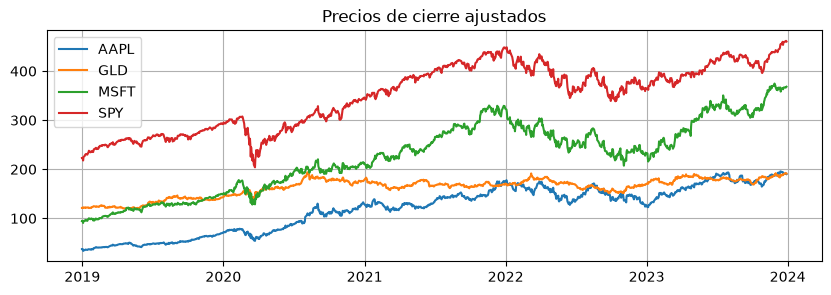

In [83]:
plt.figure(figsize=(10,3)) # Indico el tamaño
plt.plot(data["AAPL"], label="AAPL") # Defino las leyendas
plt.plot(data["GLD"], label="GLD")
plt.plot(data["MSFT"], label="MSFT")
plt.plot(data["SPY"], label="SPY")
plt.title("Precios de cierre ajustados") #Defino el título
plt.grid(True) # Le pongo una rejilla
plt.legend() # le indico que refleje las leyendas
plt.show()

Por defecto `plt.legend(loc="upper right")`

Otras opciones:
- "upper right"
- "upper left"
- "lower right"
- "lower left"
- "center"
- "center left"
- "center right"
- "upper center"
- "lower center"
- "best"

Además puedo poner un título a leyenda:

`plt.legend(title="Activos")`

Determinar el tamaño de letra

`plt.legend(title="Activos", fontsize=10)`

Determinar el número de columnas

`plt.legend(ncol=2)`

Quitar o mantener recuadro

`plt.legend(frameon=False)`

Poner leyenda fuera del cuadro:

`bbox_to_anchor` permite posicionarla con más precisión.

`plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)`

Cambiar el tamaño de los marcadores, pero debo definir previamente un marcador.

`plt.legend(markerscale=2)`

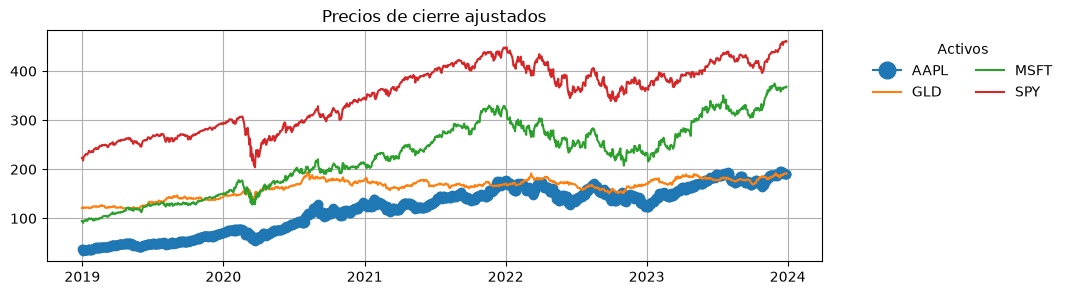

In [84]:
plt.figure(figsize=(10,3)) # Indico el tamaño
plt.plot(data["AAPL"], label="AAPL",marker="o") # Defino un marcados
plt.plot(data["GLD"], label="GLD")
plt.plot(data["MSFT"], label="MSFT")
plt.plot(data["SPY"], label="SPY")
plt.title("Precios de cierre ajustados") #Defino el título
plt.grid(True) # Le pongo una rejilla
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    title="Activos",
    fontsize=10,
    ncol=2,
    frameon=False,
    markerscale=2
)
plt.show()

Tipo de marcadores:
- marker="o"   # círculo
- marker="s"   # cuadrado
- marker="^"   # triángulo arriba
- marker="v"   # triángulo abajo
- marker="<"   # triángulo izquierda
- marker=">"   # triángulo derecha
- marker="D"   # rombo
- marker="d"   # rombo pequeño
- marker="*"   # estrella
- marker="+"   # cruz
- marker="x"   # aspa
- marker="p"   # pentágono
- marker="h"   # hexágono
- marker="H"   # hexágono alternativo
- marker="."   # punto
- marker=","   # píxel
- marker="1"   # tri_down
- marker="2"   # tri_up
- marker="3"   # tri_left
- marker="4"   # tri_right

## Ejercicio de Repaso: Análisis y Visualización de Datos Financieros

### Objetivos:
1. Descargar datos financieros de Yahoo Finance.
2. Realizar la inspección, limpieza y concatenación de datos.
3. Aplicar técnicas de slicing para análisis.
4. Visualizar los datos para un análisis preliminar.

### Instrucciones:

#### 1. Descarga y Preparación de Datos:
- Utiliza la librería `yfinance` para descargar el 'Adj Close' de los siguientes activos para el periodo del 1 de enero de 2015 al 31 de agosto de 2023:
  - Tesla, Inc. (TSLA)
  - NVIDIA Corporation (NVDA)
  - Meta Platforms, Inc. (META)
- Renombra las columnas de cada DataFrame utilizando el formato `Activo_Columna` (por ejemplo, `TSLA_AdjClose`, `NVDA_AdjClose`, etc.).
- Junta todos los DataFrames en un único DataFrame llamado `df_concatenado`, utilizando la fecha como índice.
- Después de la concatenación, crea un nuevo DataFrame llamado `df_adj_close` que contenga las columnas de precios ajustados (`Adj Close`) de cada activo.

#### 2. Inspección Inicial:
- Muestra las primeras 10 filas del DataFrame `df_adj_close` para revisar su estructura y contenido.
- Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.
- Utiliza `info()` y `describe()` para obtener una visión general de los datos.

#### 3. Slicing de Datos:
- Selecciona las filas correspondientes a los meses de julio de 2018, 2019, 2020, 2021 y 2022 y crea una nueva tabla con los precios ajustados (`Adj Close`) de esos periodo para cada activo.
- Crea una tabla con las primeras 30 observaciones del año 2023.

#### 4. Visualización de Datos:
- Genera un gráfico de líneas utilizando los métodos de visualización de pandas para mostrar la evolución de los precios ajustados de los tres activos durante el periodo completo.
- Utilizando `matplotlib`, crea un gráfico personalizado para visualizar los tres activos, incluyendo título, leyenda y cuadrícula.

#### 5. Interpretación:
- Razona en cuál de los activos analizados invertiría tu dinero.

#### 1. Descarga y Preparación de Datos:
- Utiliza la librería `yfinance` para descargar el 'Adj Close' de los siguientes activos para el periodo del 1 de enero de 2015 al 31 de agosto de 2023:
  - Tesla, Inc. (TSLA)
  - NVIDIA Corporation (NVDA)
  - Meta Platforms, Inc. (META)
- Renombra las columnas de cada DataFrame utilizando el formato `Activo_Columna` (por ejemplo, `TSLA_AdjClose`, `NVDA_AdjClose`, etc.).
- Junta todos los DataFrames en un único DataFrame llamado `df_concatenado`, utilizando la fecha como índice.
- Después de la concatenación, crea un nuevo DataFrame llamado `df_adj_close` que contenga las columnas de precios ajustados (`Adj Close`) de cada activo.

#### **Utilizamos diccionarios**

In [85]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Descarga y preparación de datos
activos = ["TSLA", "NVDA", "META"]
inicio = "2015-01-01"
fin = "2023-08-31"

# Descargar solo 'Adj Close' de cada activo y guardarlo en un diccionario
dataframes = {}
for activo in activos:
    datos = yf.download(activo, start=inicio, end=fin, auto_adjust=False, progress=False)  # Descarga uno a uno
    datos = datos.loc[:, "Adj Close"]               # Quedarnos con Adj Close
    datos.columns = [f"{activo}_AdjClose"]          # Renombrar la columna del dataframe descargado
    dataframes[activo] = datos                      # Guardar en un diccionario para luego concatenar todos

# Concatenar todos los DataFrames en uno solo (axis=1: uno al lado del otro)
df_concatenado = pd.concat(dataframes.values(), axis=1)

# Crear un nuevo DataFrame con solo las columnas de precios ajustados
df_adj_close = df_concatenado.copy()

In [86]:
type(dataframes)

dict

In [87]:
type(dataframes["TSLA"])

pandas.DataFrame

In [88]:
df_adj_close

,TSLA_AdjClose,NVDA_AdjClose,META_AdjClose
Date,,,
2015-01-02,14.620667,0.481884,77.705757
2015-01-05,14.006000,0.473745,76.457703
2015-01-06,14.085333,0.459382,75.427574
2015-01-07,14.063333,0.458185,75.427574
2015-01-08,14.041333,0.475420,77.438324
...,...,...,...
2023-08-24,230.039993,47.018688,284.029663
2023-08-25,238.589996,45.877197,282.791504
2023-08-28,238.820007,46.691692,287.506409


#### **Utiliza listas**

In [89]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Descarga y preparación de datos
activos = ["TSLA", "NVDA", "META"]
inicio = "2015-01-01"
fin = "2023-08-31"

# Descargar solo 'Adj Close' de cada activo y guardarlo en una lista
dataframes = []
for activo in activos:
    datos = yf.download(activo, start=inicio, end=fin, auto_adjust=False, progress=False)  # Descarga uno a uno
    datos = datos.loc[:, "Adj Close"]               # Quedarnos con Adj Close
    datos.columns = [f"{activo}_AdjClose"]          # Renombrar la columna del dataframe descargado
    dataframes.append(datos)                        # Guardar en una lista para luego concatenar todos

# Concatenar todos los DataFrames en uno solo
df_concatenado = pd.concat(dataframes, axis=1)

# Crear un nuevo DataFrame con solo las columnas de precios ajustados
df_adj_close = df_concatenado.copy()

In [90]:
df_adj_close

,TSLA_AdjClose,NVDA_AdjClose,META_AdjClose
Date,,,
2015-01-02,14.620667,0.481884,77.705757
2015-01-05,14.006000,0.473745,76.457703
2015-01-06,14.085333,0.459382,75.427574
2015-01-07,14.063333,0.458185,75.427574
2015-01-08,14.041333,0.475420,77.438324
...,...,...,...
2023-08-24,230.039993,47.018688,284.029663
2023-08-25,238.589996,45.877197,282.791504
2023-08-28,238.820007,46.691692,287.506409


#### **Sólo con la API**

In [91]:
# Descargamos los tres activos a la vez y nos quedamos con 'Adj Close'
# (las columnas ya llevan el nombre de cada ticker, no hace falta renombrarlas)
df_adj_close = yf.download(activos, start=inicio, end=fin, auto_adjust=False, progress=False)["Adj Close"]
df_adj_close

Ticker,META,NVDA,TSLA
Date,,,
2015-01-02,77.705757,0.481884,14.620667
2015-01-05,76.457703,0.473745,14.006000
2015-01-06,75.427574,0.459382,14.085333
2015-01-07,75.427574,0.458185,14.063333
2015-01-08,77.438324,0.475420,14.041333
...,...,...,...
2023-08-24,284.029663,47.018688,230.039993
2023-08-25,282.791504,45.877197,238.589996
2023-08-28,287.506409,46.691692,238.820007


#### 2. Inspección Inicial:
- Muestra las primeras 10 filas del DataFrame `df_adj_close` para revisar su estructura y contenido.
- Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.
- Utiliza `info()` y `describe()` para obtener una visión general de los datos.

In [92]:
# 2. Inspección inicial
# Mostrar las primeras 10 filas del DataFrame
print("Primeras 10 filas de df_adj_close:")
df_adj_close.head(10)

Primeras 10 filas de df_adj_close:


Ticker,META,NVDA,TSLA
Date,,,
2015-01-02,77.705757,0.481884,14.620667
2015-01-05,76.457703,0.473745,14.006000
2015-01-06,75.427574,0.459382,14.085333
2015-01-07,75.427574,0.458185,14.063333
2015-01-08,77.438324,0.475420,14.041333
2015-01-09,77.002495,0.477335,13.777333
2015-01-12,75.992165,0.471351,13.480667
2015-01-13,75.724724,0.470633,13.616667
2015-01-14,75.556351,0.472548,12.846000


In [93]:
# Identificar las columnas con valores nulos y su conteo
print("Valores nulos por columna:")
df_adj_close.isnull().sum()

Valores nulos por columna:


Ticker
META    0
NVDA    0
TSLA    0
dtype: int64

In [94]:
# Información general del DataFrame
print("Información del DataFrame:")
df_adj_close.info()

Información del DataFrame:
<class 'pandas.DataFrame'>
DatetimeIndex: 2180 entries, 2015-01-02 to 2023-08-30
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   META    2180 non-null   float64
 1   NVDA    2180 non-null   float64
 2   TSLA    2180 non-null   float64
dtypes: float64(3)
memory usage: 68.1 KB


In [95]:
# Estadística descriptiva
print("Estadísticas descriptivas:")
df_adj_close.describe()

Estadísticas descriptivas:


Ticker,META,NVDA,TSLA
count,2180.000000,2180.000000,2180.000000
mean,183.567658,9.738864,97.506715
std,72.653698,9.972612,109.489916
min,73.347511,0.458185,9.578000
25%,127.459236,2.583307,16.539999
50%,173.022842,5.672168,22.779000
75%,217.779194,14.497869,200.935001
max,378.554352,49.113262,409.970001


#### 3. Slicing de Datos:
- Selecciona las filas correspondientes a los meses de julio de 2018, 2019, 2020, 2021 y 2022 y crea una nueva tabla con los precios ajustados de esos periodo para cada activo.
- Crea una tabla con las primeras 30 observaciones del año 2023.

In [96]:
# 3. Slicing de datos
# Filtrar los meses de julio de 2018, 2019, 2020, 2021 y 2022:
# index.month es el mes de cada fecha e index.year.isin([...]) comprueba si el año está en la lista
julios = df_adj_close[(df_adj_close.index.month == 7) &
                      (df_adj_close.index.year.isin([2018, 2019, 2020, 2021, 2022]))]
julios

Ticker,META,NVDA,TSLA
Date,,,
2018-07-02,195.487671,5.982333,22.337999
2018-07-03,190.901611,5.848976,20.724001
2018-07-05,196.567368,5.994432,20.610666
2018-07-06,201.302002,6.108035,20.593332
2018-07-09,202.797684,6.155451,21.233999
...,...,...,...
2022-07-25,165.069016,16.957897,268.433319
2022-07-26,157.640167,16.468798,258.859985
2022-07-27,167.971237,17.720919,274.820007


In [97]:
# Filtrar las primeras 30 observaciones de 2023
df_2023 = df_adj_close.loc["2023"]   # todas las filas de 2023
df_primero_30 = df_2023.iloc[:30]    # las 30 primeras por posición
print("Primeras 30 observaciones de 2023:")
df_primero_30

Primeras 30 observaciones de 2023:


Ticker,META,NVDA,TSLA
Date,,,
2023-01-03,123.556618,14.267298,108.099998
2023-01-04,126.161667,14.699852,113.639999
2023-01-05,125.735733,14.217466,110.339996
2023-01-06,128.786545,14.809486,113.059998
2023-01-09,128.241745,15.575924,119.769997
2023-01-10,131.728333,15.855989,118.849998
2023-01-11,131.629318,15.947680,123.220001
2023-01-12,135.413071,16.455978,123.559998
2023-01-13,135.680496,16.842688,122.400002


**RECORDATORIO**

`df_primero_30 = df_2023.iloc[:30]` como solo hemos puesto un selector, Pandas interpreta que te refieres a las filas.

#### 4. Visualización de Datos:
- Genera un gráfico de líneas utilizando los métodos de visualización de pandas para mostrar la evolución de los precios ajustados de los tres activos durante el periodo completo.
- Utilizando `matplotlib`, crea un gráfico personalizado para visualizar los tres activos, incluyendo título, leyenda y cuadrícula.

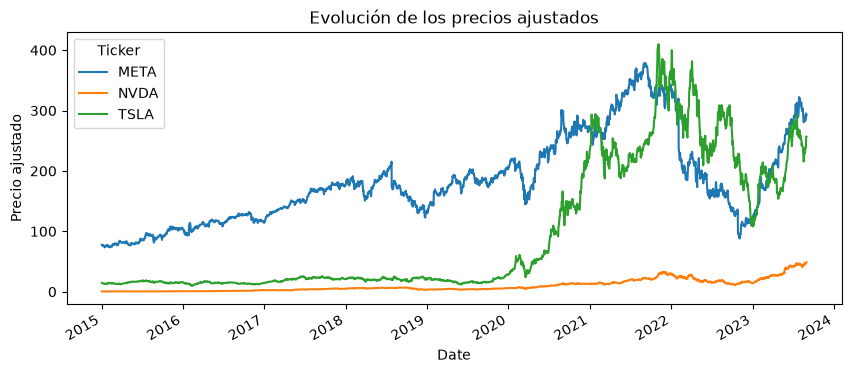

In [98]:
# 4. Visualización de datos
# Gráfico de líneas de precios ajustados con los métodos de pandas
df_adj_close.plot(figsize=(10, 4), title="Evolución de los precios ajustados", ylabel="Precio ajustado")
plt.show()

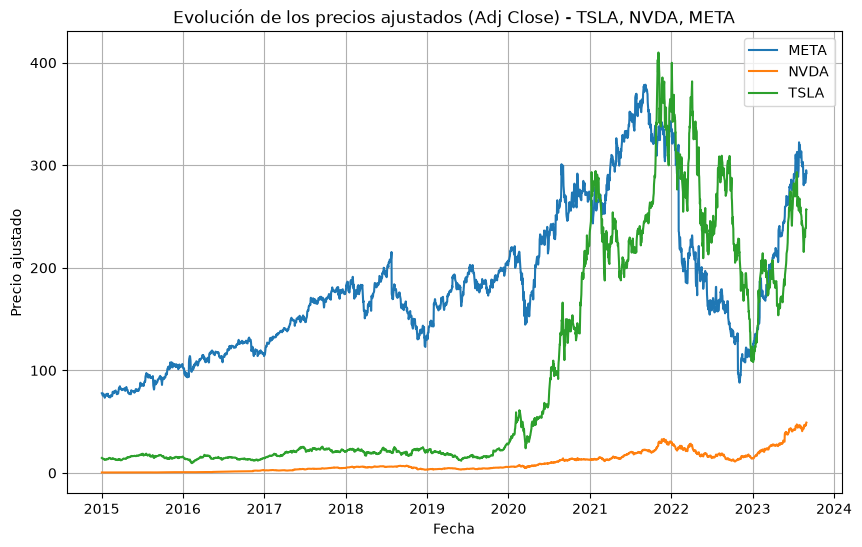

In [99]:
# Gráfico personalizado usando matplotlib: una línea por activo
plt.figure(figsize=(10, 6))
for columna in df_adj_close.columns:
    plt.plot(df_adj_close.index, df_adj_close[columna], label=columna)

plt.title("Evolución de los precios ajustados (Adj Close) - TSLA, NVDA, META")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado")
plt.legend()
plt.grid(True)
plt.show()

#### 5. Interpretación:
- Razona en cuál de los activos analizados invertirías tu dinero.

Pista: compara la rentabilidad y el riesgo de cada activo.

**Fórmulas:**

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) \qquad \mu_{anual} = \bar{r} \times 252 \qquad \sigma_{anual} = \sigma_r \times \sqrt{252}$$

$$\text{Rentabilidad por unidad de riesgo} = \frac{\mu_{anual}}{\sigma_{anual}}$$

In [100]:
import numpy as np

# 5. Interpretación
# Rentabilidades logarítmicas diarias: logaritmo del precio de hoy menos el de ayer
rent_log = np.log(df_adj_close).diff().dropna()

# Anualizamos: la media se multiplica por 252 días de mercado y la desviación por la raíz de 252
resumen = pd.DataFrame({
    "Rentabilidad anual": rent_log.mean() * 252,
    "Volatilidad anual": rent_log.std() * np.sqrt(252),
})
# Rentabilidad por cada unidad de riesgo asumida
resumen["Rentabilidad / Volatilidad"] = resumen["Rentabilidad anual"] / resumen["Volatilidad anual"]
resumen

# NVDA ha sido el activo con mayor rentabilidad y también con mayor rentabilidad por unidad de riesgo
# en el periodo analizado. TSLA ha tenido la mayor volatilidad. Rentabilidades pasadas no garantizan
# rentabilidades futuras: la decisión dependerá también de la tolerancia al riesgo del inversor.

,Rentabilidad anual,Volatilidad anual,Rentabilidad / Volatilidad
Ticker,,,
META,0.153218,0.384707,0.398273
NVDA,0.534784,0.482750,1.107785
TSLA,0.331480,0.567225,0.584389
